<a href="https://colab.research.google.com/github/ShamaimI/ANN-DL/blob/main/Lab3_ANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ANN LAB 03

Lab Task 1: Dataset Loading and Visualization
1.	Select and load a suitable binary-classification dataset from Kaggle or the UCI Machine Learning Repository.
2.	Perform basic data inspection, including dataset shape, features, target variable, and missing values.
3.	Visualize the dataset using appropriate plots to understand the distribution of the classes.
4.	Split the dataset into training and testing sets and prepare the features for model training.



Dataset loaded successfully.
Dataset Shape: (768, 9)
   pregnancies  glucose  blood_pressure  skin_thickness  insulin   bmi  \
0            6      148              72              35        0  33.6   
1            1       85              66              29        0  26.6   
2            8      183              64               0        0  23.3   
3            1       89              66              23       94  28.1   
4            0      137              40              35      168  43.1   
5            5      116              74               0        0  25.6   
6            3       78              50              32       88  31.0   
7           10      115               0               0        0  35.3   
8            2      197              70              45      543  30.5   
9            8      125              96               0        0   0.0   

   diabetes_pedigree_function  age  outcome  
0                       0.627   50        1  
1                       0.351   31      

/tmp/ipykernel_946/903375757.py:25: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mean(), inplace=True)


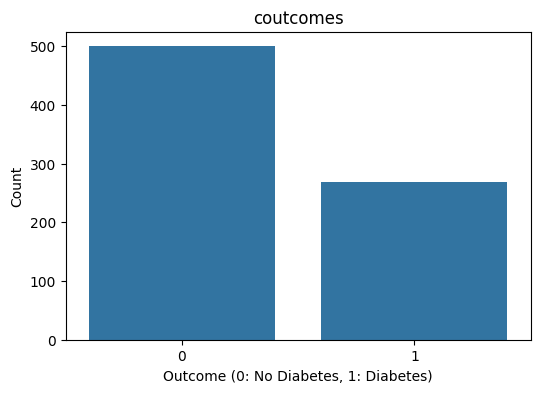

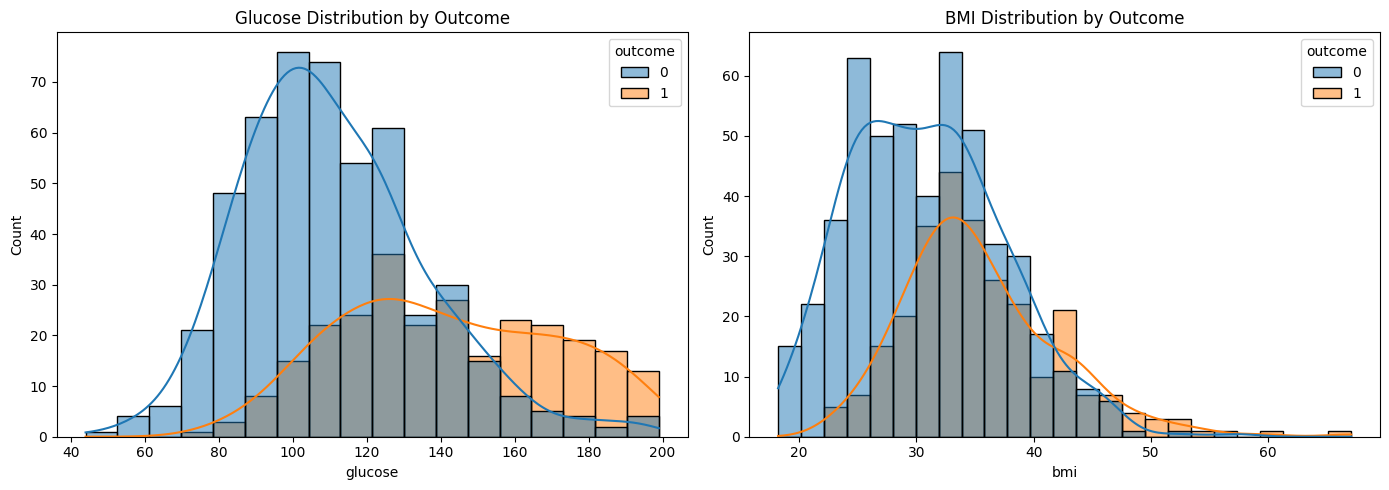

Original dataset: (768, 9)
Training features: (614, 8)
Testing features: (154, 8)
Training target: (614,)
Testing target: (154,)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

column_names = ['pregnancies', 'glucose', 'blood_pressure', 'skin_thickness', 'insulin', 'bmi', 'diabetes_pedigree_function', 'age', 'outcome']
dataset_url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'
df = pd.read_csv(dataset_url, names=column_names)

print("Dataset loaded successfully.")

print("Dataset Shape:", df.shape)
print( df.head(10))
df.info()
print("checking null values:", df.isnull().sum())

for col in ['glucose', 'blood_pressure', 'skin_thickness', 'insulin', 'bmi']:
    print(f"{col}: {(df[col] == 0).sum()}")

df[['glucose', 'blood_pressure', 'skin_thickness', 'insulin', 'bmi']] = df[['glucose', 'blood_pressure', 'skin_thickness', 'insulin', 'bmi']].replace(0, np.nan)

for col in ['glucose', 'blood_pressure', 'skin_thickness', 'insulin', 'bmi']:
    df[col].fillna(df[col].mean(), inplace=True)

print("missing value impuation:")
print(df.isnull().sum())

plt.figure(figsize=(6, 4))
sns.countplot(x='outcome', data=df)
plt.title('coutcomes')
plt.xlabel('Outcome (0: No Diabetes, 1: Diabetes)')
plt.ylabel('Count')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df, x='glucose', hue='outcome', kde=True, ax=axes[0])
axes[0].set_title('Glucose Distribution by Outcome')
sns.histplot(df, x='bmi', hue='outcome', kde=True, ax=axes[1])
axes[1].set_title('BMI Distribution by Outcome')
plt.tight_layout()
plt.show()

X = df.drop('outcome', axis=1)
y = df['outcome']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Original dataset: {df.shape}")
print(f"Training features: {X_train.shape}")
print(f"Testing features: {X_test.shape}")
print(f"Training target: {y_train.shape}")
print(f"Testing target: {y_test.shape}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

globals()['X_train_scaled'] = X_train_scaled
globals()['X_test_scaled'] = X_test_scaled
globals()['y_train'] = y_train
globals()['y_test'] = y_test
globals()['df'] = df


 Lab Task 2: Basic Perceptron Implementation 1. Implement a Perceptron classifier from scratch using Python and NumPy, without using a built-in Perceptron classifier. 2. Initialize the weights and bias and implement the perceptron prediction and weight-update rules. 3. Train the perceptron on the training dataset for a specified number of epochs. 4. Evaluate the trained perceptron on the test dataset and report its classification accuracy.

 Lab Task 3: Perceptron Learning Curve and Weight Visualization
1.	Modify your perceptron implementation to record the training error/loss after every epoch.
2.	Plot the learning curve showing the change in error over training epochs.
3.	Display the final values of the weights and bias after training.
4.	Visualize the final decision boundary, where applicable, and explain how it separates the two classes.


training set [[-0.85135507 -1.0575301  -0.82797293 ... -0.76981811  0.31079384
  -0.79216928]
 [ 0.35657564  0.14339202  0.47653222 ... -0.41783762 -0.11643851
   0.56103382]
 [-0.5493724  -0.55714588 -1.15409922 ...  0.35945263 -0.76486207
  -0.70759409]
 ...
 [-0.85135507 -0.82401747 -0.17572035 ...  0.82875995 -0.78607218
  -0.28471812]
 [ 1.86648903 -0.3569922  -0.17572035 ... -0.72582055 -1.01938346
   0.56103382]
 [ 0.05459296  0.74385309 -1.15409922 ... -0.43250348 -0.57700104
   0.30730824]]
training set [0 0 0 0 0 1 1 1 0 0 1 0 0 0 1 0 1 0 0 0 0 0 1 1 0 0 0 0 0 1 0 0 1 1 0 0 1
 0 1 1 1 0 1 1 0 1 0 0 0 1 1 0 0 1 1 0 1 0 0 1 0 0 0 1 1 1 1 1 1 0 0 1 1 0
 1 1 0 1 1 1 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 0 0
 0 0 1 0 1 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 1 0 1 1 0 0 0 0 1 0 0 0
 0 0 0 0 1 0 1 0 1 0 1 0 0 0 0 1 0 0 0 0 0 1 1 0 0 0 0 1 1 0 0 0 1 1 0 0 0
 0 0 1 0 0 0 1 1 1 0 0 0 0 1 1 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 1 1 0 0
 1 0 0 1 1 0 1 0 0 0 1 0 0 0 0 1

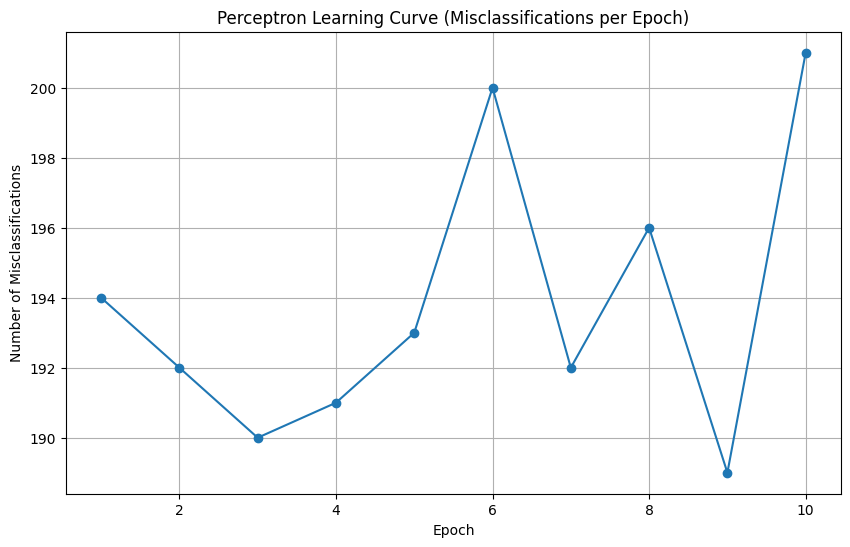

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

x_train=np.array(X_train_scaled)
y_train=np.array(y_train)

x_test=np.array(X_test_scaled)
y_test=np.array(y_test)

learning_rate, epochs= 0.1, 10

weight=np.random.randn(x_train.shape[1])*np.sqrt(2/x_train.shape[1])
bias=0.0
print("training set",x_train)
print("training set",y_train)
print("testing set",x_test)
print("testing set",y_test)
print("initial weights", weight)
print("initial bias", bias)

errors_per_epoch = []

for epoch in range(epochs):
    epoch_errors = 0
    for x_i, y_true in zip(X_train_scaled, y_train):
        linear_output = np.dot(x_i, weights) + bias
        y_pred = 1 if linear_output >= 0 else 0
        error = y_true - y_pred

        if error != 0:
            weights += learning_rate * error * x_i
            bias += learning_rate * error
            epoch_errors += 1

    errors_per_epoch.append(epoch_errors)
    print(f"Epoch {epoch+1}/{epochs}, Misclassifications: {epoch_errors}")

prediction=np.array([1 if (np.dot(x, weight)+bias)>=0 else 0 for x in x_test])
accuracy=np.mean(prediction == y_test)

print(f"Accuracy: {accuracy*100:.2f}")
print("updated weights", weight)
print("updated bias", bias)

plt.figure(figsize=(10, 6))
plt.plot(range(1, epochs + 1), errors_per_epoch, marker='o')
plt.title('Perceptron Learning Curve (Misclassifications per Epoch)')
plt.xlabel('Epoch')
plt.ylabel('Number of Misclassifications')
plt.grid(True)
plt.show()

globals()['perceptron_weights_default_init'] = weights
globals()['perceptron_bias_default_init'] = bias
globals()['perceptron_errors_per_epoch_default_init'] = errors_per_epoch



Lab Task 4: Gaussian Weight Initialization
1.	Re-initialize the perceptron's weights using Gaussian/Normal initialization with a suitable mean and standard deviation.
2.	Train the perceptron using the same dataset, hyperparameters, and training procedure used previously.
3.	Record the number of epochs required for the perceptron to converge and plot its learning curve.
4.	Compare the Gaussian-initialized model with the default/randomly initialized model in terms of convergence and final weights.


Epoch 1/10, Misclassifications: 195
Epoch 2/10, Misclassifications: 196
Epoch 3/10, Misclassifications: 200
Epoch 4/10, Misclassifications: 202
Epoch 5/10, Misclassifications: 189
Epoch 6/10, Misclassifications: 183
Epoch 7/10, Misclassifications: 191
Epoch 8/10, Misclassifications: 184
Epoch 9/10, Misclassifications: 198
Epoch 10/10, Misclassifications: 192
Accuracy: 70.78
updated weights [ 0.23145783  0.29939441  0.16164665 -0.01431028  0.09398963  0.10876488
  0.13975305  0.02804012]
updated bias -2.7755575615628914e-17


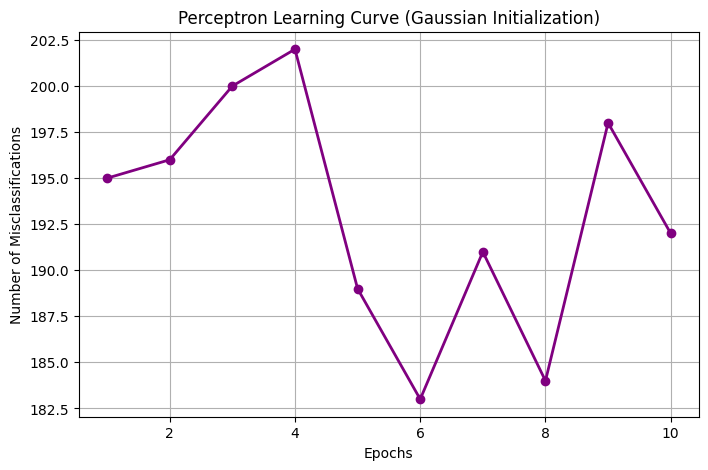

In [ ]:
mean=0.0
std=0.01
weights=np.random.normal(loc=mean, scale=std, size=x_train.shape[1])
bias=0.0

errors_per_epoch = []
converged_at = None

for epoch in range(epochs):
    epoch_errors = 0
    for x_i, y_true in zip(x_train, y_train):
        linear_output = np.dot(x_i, weights) + bias
        y_pred= 1 if linear_output>=0 else 0
        error=y_true-y_pred

        if error != 0:
            weights += learning_rate * error * x_i
            bias += learning_rate * error
            epoch_errors +=1

    errors_per_epoch.append(epoch_errors)
    print(f"Epoch {epoch+1}/{epochs}, Misclassifications: {epoch_errors}")

    if epoch_errors == 0 and converged_at is None:
        converged_at = epoch + 1

prediction=np.array([1 if (np.dot(x, weights)+bias)>=0 else 0 for x in x_test])
accuracy=np.mean(prediction == y_test)

print(f"Accuracy: {accuracy*100:.2f}")
print("updated weights", weights)
print("updated bias", bias)

plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), errors_per_epoch, marker='o', color='purple', linewidth=2)
plt.title('Perceptron Learning Curve (Gaussian Initialization)')
plt.xlabel('Epochs')
plt.ylabel('Number of Misclassifications')
plt.grid(True)
plt.show()



Lab Task 5: Xavier/Glorot Initialization
1.	Implement Xavier/Glorot initialization for the perceptron's weights.
2.	Train the perceptron using Xavier-initialized weights while keeping the dataset and training settings unchanged.
3.	Record the number of epochs required for convergence and plot the corresponding learning curve.
4.	Compare the results with Gaussian initialization and discuss how the initialization affected the training process.


Initial Xavier Weights:
 [-0.25662448  0.05228941 -0.54258358  0.17710574 -0.28314379 -0.13750575
 -0.28364722  0.87317231]
Initial Bias:
 0.0
Epoch 1/10, Misclassifications: 201
Epoch 2/10, Misclassifications: 188
Epoch 3/10, Misclassifications: 196
Epoch 4/10, Misclassifications: 189
Epoch 5/10, Misclassifications: 190
Epoch 6/10, Misclassifications: 191
Epoch 7/10, Misclassifications: 195
Epoch 8/10, Misclassifications: 204
Epoch 9/10, Misclassifications: 195
Epoch 10/10, Misclassifications: 193
Accuracy: 66.88
updated weights [ 0.15523268  0.49312836  0.32896542  0.06195448  0.11457576  0.10529575
 -0.15612694  0.03361888]
updated bias -0.20000000000000004


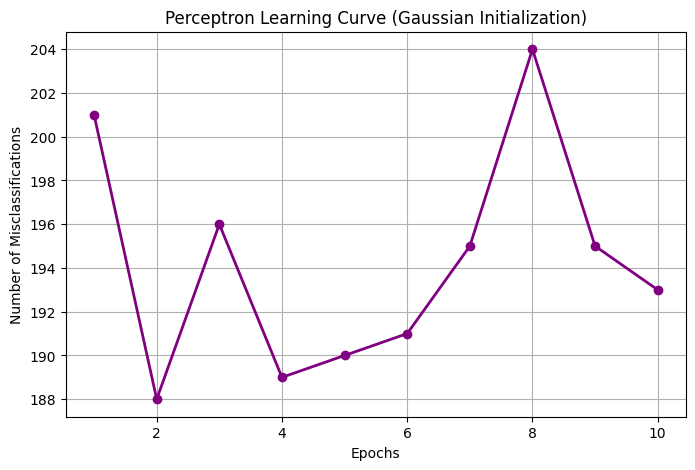

In [ ]:
fan_in = x_train.shape[1]
fan_out = 1
xavier_std = np.sqrt(2.0 / (fan_in + fan_out))

weights = np.random.normal(loc=0.0, scale=xavier_std, size=fan_in)
bias = 0.0
errors_per_epoch = []

print("Initial Xavier Weights:\n", weights)
print("Initial Bias:\n", bias)

converged_at = None
for epoch in range(epochs):
    epoch_errors = 0
    for x_i, y_true in zip(x_train, y_train):
        linear_output = np.dot(x_i, weights) + bias
        y_pred = 1 if linear_output >= 0 else 0
        error = y_true - y_pred

        if error != 0:
            weights += learning_rate * error * x_i
            bias += learning_rate * error
            epoch_errors += 1

    errors_per_epoch.append(epoch_errors)
    print(f"Epoch {epoch+1}/{epochs}, Misclassifications: {epoch_errors}")

    if epoch_errors == 0 and converged_at is None:
        converged_at = epoch + 1

prediction=np.array([1 if (np.dot(x, weights)+bias)>=0 else 0 for x in x_test])
accuracy=np.mean(prediction == y_test)

print(f"Accuracy: {accuracy*100:.2f}")
print("updated weights", weights)
print("updated bias", bias)

plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), errors_per_epoch, marker='o', color='purple', linewidth=2)
plt.title('Perceptron Learning Curve (Gaussian Initialization)')
plt.xlabel('Epochs')
plt.ylabel('Number of Misclassifications')
plt.grid(True)
plt.show()



Lab Task 6: He/Kaiming Initialization
1.	Implement He/Kaiming initialization for the perceptron's weights.
2.	Train the perceptron using the He-initialized weights on the same training dataset.
3.	Record the convergence behavior, number of epochs, final weights, and test accuracy.
4.	Compare the He initialization results with Gaussian and Xavier initialization.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

x_train=np.array(X_train_scaled)
y_train=np.array(y_train)

x_test=np.array(X_test_scaled)
y_test=np.array(y_test)

learning_rate, epochs= 0.1, 10

weight=np.random.randn(x_train.shape[1])*np.sqrt(2/x_train.shape[1])
bias=0.0
print("training set",x_train)
print("training set",y_train)
print("testing set",x_test)
print("testing set",y_test)
print("initial weights", weight)
print("initial bias", bias)

errors_per_epoch = []

for epoch in range(epochs):
    epoch_errors = 0
    for x_i, y_true in zip(X_train_scaled, y_train):
        linear_output = np.dot(x_i, weights) + bias
        y_pred = 1 if linear_output >= 0 else 0
        error = y_true - y_pred

        if error != 0:
            weights += learning_rate * error * x_i
            bias += learning_rate * error
            epoch_errors += 1

    errors_per_epoch.append(epoch_errors)
    print(f"Epoch {epoch+1}/{epochs}, Misclassifications: {epoch_errors}")

prediction=np.array([1 if (np.dot(x, weight)+bias)>=0 else 0 for x in x_test])
accuracy=np.mean(prediction == y_test)

print(f"Accuracy: {accuracy*100:.2f}")
print("updated weights", weight)
print("updated bias", bias)

plt.figure(figsize=(10, 6))
plt.plot(range(1, epochs + 1), errors_per_epoch, marker='o')
plt.title('Perceptron Learning Curve (Misclassifications per Epoch)')
plt.xlabel('Epoch')
plt.ylabel('Number of Misclassifications')
plt.grid(True)
plt.show()

globals()['perceptron_weights_default_init'] = weights
globals()['perceptron_bias_default_init'] = bias
globals()['perceptron_errors_per_epoch_default_init'] = errors_per_epoch



Lab Task 7: Orthogonal Initialization
1.	Implement Orthogonal initialization for the perceptron's weight matrix.
2.	Train the perceptron using the orthogonally initialized weights while keeping all other experimental settings consistent.
3.	Plot the learning curve and record the number of epochs required for convergence.
4.	Compare Orthogonal initialization with Gaussian, Xavier, and He initialization based on convergence behavior and final model parameters.


Initial Orthogonal Weights:
 [-0.00878919  0.48087831  0.22375905 -0.54648581  0.52910457 -0.02332938
 -0.14304702 -0.34497186]
Initial Weights L2 Norm (Verification): 0.9999999999999998
Initial Bias:
 0.0
Epoch 1/10, Misclassifications: 194
Epoch 2/10, Misclassifications: 195
Epoch 3/10, Misclassifications: 190
Epoch 4/10, Misclassifications: 195
Epoch 5/10, Misclassifications: 193
Epoch 6/10, Misclassifications: 201
Epoch 7/10, Misclassifications: 199
Epoch 8/10, Misclassifications: 180
Epoch 9/10, Misclassifications: 198
Epoch 10/10, Misclassifications: 196

Convergence status: Did not fully converge (Non-linearly separable data)
Orthogonal Final Accuracy: 66.88%
Updated weights:
 [ 0.22733766  0.46276163  0.16261363  0.31660861  0.39681075  0.34132209
 -0.03595765 -0.06277447]
Updated bias:
 -0.10000000000000003


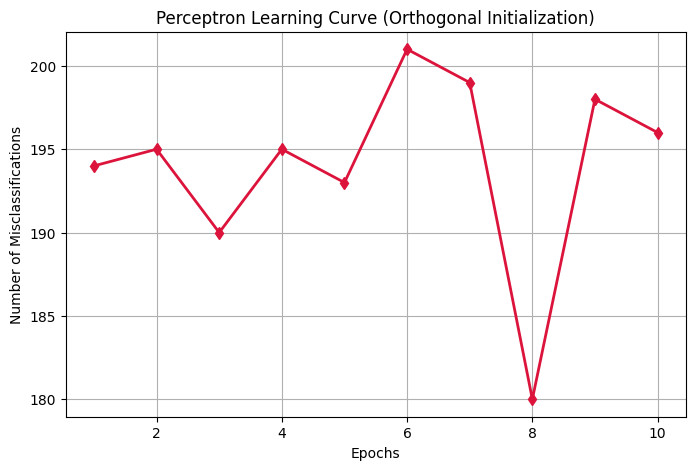

In [ ]:
flat_shape = x_train.shape[1]
random_matrix = np.random.randn(flat_shape, flat_shape)
q, r = np.linalg.qr(random_matrix)
weights = q[:, 0]
bias = 0.0

print("Initial Orthogonal Weights:\n", weights)
print("Initial Weights L2 Norm (Verification):", np.linalg.norm(weights))
print("Initial Bias:\n", bias)

orthogonal_errors = []
converged_at = None

for epoch in range(epochs):
    epoch_errors = 0
    for x_i, y_true in zip(x_train, y_train):
        linear_output = np.dot(x_i, weights) + bias
        y_pred = 1 if linear_output >= 0 else 0
        error = y_true - y_pred

        if error != 0:
            weights += learning_rate * error * x_i
            bias += learning_rate * error
            epoch_errors += 1

    orthogonal_errors.append(epoch_errors)
    print(f"Epoch {epoch+1}/{epochs}, Misclassifications: {epoch_errors}")

    if epoch_errors == 0 and converged_at is None:
        converged_at = epoch + 1

print(f"\nConvergence status: {'Converged at epoch ' + str(converged_at) if converged_at else 'Did not fully converge (Non-linearly separable data)'}")

prediction = np.array([1 if (np.dot(x, weights) + bias) >= 0 else 0 for x in x_test])
accuracy = np.mean(prediction == y_test)

print(f"Orthogonal Final Accuracy: {accuracy * 100:.2f}%")
print("Updated weights:\n", weights)
print("Updated bias:\n", bias)

plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), orthogonal_errors, marker='d', color='crimson', linewidth=2)
plt.title('Perceptron Learning Curve (Orthogonal Initialization)')
plt.xlabel('Epochs')
plt.ylabel('Number of Misclassifications')
plt.grid(True)
plt.show()


Lab Task 8: Comparative Analysis of Weight Initialization Techniques
1.	Train the same perceptron using Gaussian, Xavier, He, and Orthogonal initialization on the same dataset.
2.	Record the number of epochs, final training error, test accuracy, and final weight values for each initialization technique.
3.	Plot the learning curves of all initialization techniques and compare their convergence behavior.
4.	Write a short analysis explaining why different initialization techniques may produce different training behavior.



Lab Task 9: Experimental Study and Interpretation
1.	Select a different suitable binary-classification dataset and repeat the perceptron experiment using Gaussian, Xavier, He, and Orthogonal initialization.
2.	Conduct multiple training runs for each initialization technique using different random seeds.
3.	Calculate and compare the average convergence epochs and average test accuracy across the runs.
4.	Based on your experimental results, discuss how weight initialization, dataset characteristics, and randomness can influence perceptron training.
